# 06 — Final model selection with PLP-RASTA

## 1. Objective

Notebook 05 compared four feature representations using the paper's 12-second feature-comparison
protocol. In the recovered corpus, **20 PLP-RASTA** obtained the lowest WER for most model orders,
whereas the paper reports **20 m-FCC** as its best representation.

This notebook therefore optimizes the model that actually performed best in **our recovered data**:

**20 PLP-RASTA → 6 / 12 / 18 s training → M = 2 / 4 / 8 / 16 / 32 / 64 →
10 repeated call-level splits → WER → final configuration selection**

### Paper versus this project

`[PAPER]`

- investigated training durations of **6, 12 and 18 seconds**;
- investigated `M = {2,4,8,16,32,64}`;
- used ten random-selection cross-validation runs;
- reported that at least 12 seconds and relatively high model order were useful;
- selected **M = 64** on average;
- later found **20 m-FCC** superior to standard MFCC and PLP-RASTA.

`[OBSERVED — notebook 05]`

- the recovered-data feature comparison instead favored **20 PLP-RASTA**;
- at 12 seconds, the best observed region was around intermediate/high GMM orders rather than forcing
  the paper's feature choice.

### Decision rule

This notebook reports two selections:

1. **Empirical best:** configuration with the minimum mean WER.
2. **Recommended parsimonious configuration:** the lowest-complexity GMM whose mean WER lies within
   **one standard error of the empirical best**.

The second rule avoids selecting a much larger model for a difference that is smaller than the
experimental uncertainty.

### Important production-model note

The selected training duration is an **experimental diagnostic**, not a rule that the eventual
production GMM must discard the remaining labelled data.

After choosing the feature representation and model order here, the next detector notebook should
train/calibrate its deployable models using an explicit leakage-free protocol and may use more labelled
training material as appropriate.

No pond recordings are used here.

In [1]:
from pathlib import Path
import json
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from scipy.stats import t as student_t
from sklearn.cluster import kmeans_plusplus
from sklearn.exceptions import ConvergenceWarning
from sklearn.mixture import GaussianMixture

pd.set_option("display.width", 180)
pd.set_option("display.max_rows", 160)
pd.set_option("display.max_columns", 80)

CWD = Path.cwd().resolve()
REPO_ROOT = CWD.parent if CWD.name == "notebooks" else CWD

PROCESSED_DIR = REPO_ROOT / "data" / "processed"

CALLS_PATH = PROCESSED_DIR / "calls.csv"

FEATURE_COMPARISON_DIR = (
    PROCESSED_DIR / "feature_comparison"
)
FEATURE_CACHE_PATH = (
    FEATURE_COMPARISON_DIR / "call_feature_sets.joblib"
)
FEATURE05_SUMMARY_PATH = (
    FEATURE_COMPARISON_DIR / "wer_summary.csv"
)

RESULTS_DIR = (
    PROCESSED_DIR / "final_model_selection"
)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

if not CALLS_PATH.exists():
    raise FileNotFoundError(
        f"Missing {CALLS_PATH}. Run notebook 02 first."
    )

if not FEATURE_CACHE_PATH.exists():
    raise FileNotFoundError(
        f"Missing {FEATURE_CACHE_PATH}. "
        "Run notebook 05_feature_comparison first so PLP-RASTA features are cached."
    )

print("Repository root :", REPO_ROOT)
print("Feature cache   :", FEATURE_CACHE_PATH)
print("Results         :", RESULTS_DIR)

Repository root : C:\Users\sofia\Projects\PUCE\frog-presence-replication
Feature cache   : C:\Users\sofia\Projects\PUCE\frog-presence-replication\data\processed\feature_comparison\call_feature_sets.joblib
Results         : C:\Users\sofia\Projects\PUCE\frog-presence-replication\data\processed\final_model_selection


## 2. Load the call table and cached PLP-RASTA features

Notebook 05 stores all feature matrices by complete call. This notebook deliberately reuses that cache
instead of extracting PLP-RASTA again.

That guarantees the representation being optimized here is **exactly the same representation that won
the feature-comparison experiment**.

In [2]:
calls = pd.read_csv(
    CALLS_PATH
).copy().reset_index(drop=True)

required = {
    "code",
    "species",
    "seconds",
    "frames",
}

missing = required - set(
    calls.columns
)

if missing:
    raise ValueError(
        f"calls.csv is missing required columns: {sorted(missing)}"
    )

calls["call_id"] = [
    f"call_{i:04d}"
    for i in range(len(calls))
]

CALLS_BY_ID = calls.set_index(
    "call_id",
    drop=False,
)

CALL_FEATURES = joblib.load(
    FEATURE_CACHE_PATH
)

EXPECTED_CALL_IDS = set(
    calls["call_id"]
)

CACHE_CALL_IDS = set(
    CALL_FEATURES
)

if EXPECTED_CALL_IDS != CACHE_CALL_IDS:
    missing_from_cache = (
        EXPECTED_CALL_IDS
        - CACHE_CALL_IDS
    )
    extra_in_cache = (
        CACHE_CALL_IDS
        - EXPECTED_CALL_IDS
    )

    raise RuntimeError(
        "The notebook-05 feature cache does not match calls.csv. "
        f"Missing={len(missing_from_cache)}, extra={len(extra_in_cache)}."
    )

PLP_FEATURE_NAME = "20_PLP_RASTA"

bad = []

for call_id in calls["call_id"]:
    feature_sets = CALL_FEATURES[
        call_id
    ]

    if PLP_FEATURE_NAME not in feature_sets:
        bad.append(
            (call_id, "missing")
        )
        continue

    X = np.asarray(
        feature_sets[PLP_FEATURE_NAME]
    )

    if (
        X.ndim != 2
        or X.shape[1] != 20
        or len(X) == 0
        or not np.isfinite(X).all()
    ):
        bad.append(
            (call_id, X.shape)
        )

if bad:
    raise RuntimeError(
        f"Invalid PLP-RASTA features for {len(bad)} calls. First entries: {bad[:5]}"
    )

print("Calls loaded       :", len(calls))
print("PLP feature matrices:", len(CALL_FEATURES))
print("PLP dimensions     : 20")
print("Feature-cache check: OK")

Calls loaded       : 1461
PLP feature matrices: 1461
PLP dimensions     : 20
Feature-cache check: OK


## 3. Species inventory and usable classes

The experiment requires **18 seconds of training plus at least some remaining validation material**.

`f09` remains excluded because the recovered labelled corpus contains only about 1.18 seconds for that
class.

The resulting nine-class cohort is the same recovered-data cohort used in notebooks 03 and 05.

In [3]:
species_inventory = (
    calls.groupby(
        ["code", "species"],
        as_index=False,
    )
    .agg(
        calls=("call_id", "size"),
        seconds=("seconds", "sum"),
    )
    .sort_values("code")
)

species_inventory["seconds"] = (
    species_inventory["seconds"]
    .round(3)
)

USABLE_CODES = tuple(
    species_inventory.loc[
        (
            species_inventory["seconds"] > 18
        )
        & (
            species_inventory["code"] != "f09"
        ),
        "code",
    ]
)

display(
    species_inventory.assign(
        used=species_inventory[
            "code"
        ].isin(USABLE_CODES)
    )
)

print("Usable classes:", USABLE_CODES)
print("Number of classes:", len(USABLE_CODES))

,code,species,calls,seconds,used
0,f01,Boana alfaroi,98,44.72,True
1,f02,Dendropsophus bifurcus,99,41.72,True
2,f03,Boana cinerascens,169,102.58,True
3,f04,Pristimantis conspicillatus,186,77.94,True
4,f05,Leptodactylus discodactylus,340,114.36,True
5,f06,Osteocephalus fuscifacies,54,24.94,True
6,f07,Boana lanciformis,101,57.84,True
7,f08,Rhinella margaritifera,96,102.66,True
8,f09,Dendropsophus parviceps,2,1.18,False
9,f10,Engystomops petersi,316,134.00,True


Usable classes: ('f01', 'f02', 'f03', 'f04', 'f05', 'f06', 'f07', 'f08', 'f10')
Number of classes: 9


## 4. Experiment configuration

The grid intentionally mirrors the paper's parameter investigation, but with the feature representation
selected by our own notebook-05 results.

For a given `duration × repeat`, **the same train/validation call split is reused across all six values
of M**. That makes model-order comparisons paired and fair.

In [4]:
TRAINING_DURATIONS = (
    6,
    12,
    18,
)

N_COMPONENTS_GRID = (
    2,
    4,
    8,
    16,
    32,
    64,
)

N_REPEATS = 10
BASE_SEED = 20260814

RUN_FULL_EXPERIMENT = True
STORE_CALL_PREDICTIONS = True

print(
    "Conditions:",
    len(TRAINING_DURATIONS)
    * len(N_COMPONENTS_GRID)
    * N_REPEATS,
)

print(
    "GMM fits:",
    len(TRAINING_DURATIONS)
    * len(N_COMPONENTS_GRID)
    * N_REPEATS
    * len(USABLE_CODES),
)

Conditions: 180
GMM fits: 1620


## 5. Reproducible complete-call train/validation selection

The split rule is kept consistent with notebooks 03 and 05:

1. randomly permute the complete calls of one species;
2. accumulate whole calls until the requested duration is reached or slightly exceeded;
3. use every remaining call for validation;
4. never cut a call in half;
5. never split frames from one call across train and validation.

The paper calls its procedure “10-fold cross-validation with random segment selection” but does not
fully specify a conventional mutually exclusive K-fold construction. These ten reproducible random
call selections remain a `[REPLICATION DECISION]`.

In [5]:
def species_number(code):
    digits = "".join(
        ch
        for ch in str(code)
        if ch.isdigit()
    )

    return int(digits) if digits else 0


def select_training_calls(
    code,
    target_seconds,
    repeat,
):
    subset = (
        calls.loc[
            calls["code"] == code
        ]
        .copy()
        .reset_index(drop=True)
    )

    total_available = float(
        subset["seconds"].sum()
    )

    if total_available <= target_seconds:
        raise ValueError(
            f"{code}: {total_available:.3f}s available, "
            f"not enough for {target_seconds}s plus validation."
        )

    # Same split-seed convention used by notebooks 03/05.
    seed = (
        BASE_SEED
        + repeat * 10_000
        + target_seconds * 100
        + species_number(code)
    )

    rng = np.random.default_rng(
        seed
    )

    order = rng.permutation(
        len(subset)
    )

    train_ids = []
    actual_seconds = 0.0

    for position in order:
        row = subset.iloc[
            position
        ]

        train_ids.append(
            row["call_id"]
        )

        actual_seconds += float(
            row["seconds"]
        )

        if actual_seconds >= target_seconds:
            break

    if len(train_ids) >= len(subset):
        raise RuntimeError(
            f"{code}: split leaves no validation calls."
        )

    train_ids = tuple(
        train_ids
    )

    train_set = set(
        train_ids
    )

    validation_ids = tuple(
        call_id
        for call_id in subset["call_id"]
        if call_id not in train_set
    )

    assert set(train_ids).isdisjoint(
        validation_ids
    )

    return {
        "code": code,
        "seed": seed,
        "train_ids": train_ids,
        "validation_ids": validation_ids,
        "target_seconds": target_seconds,
        "actual_seconds": actual_seconds,
        "overshoot_seconds": (
            actual_seconds
            - target_seconds
        ),
    }


def build_split(
    target_seconds,
    repeat,
):
    split = {}

    for code in USABLE_CODES:
        split[code] = (
            select_training_calls(
                code=code,
                target_seconds=target_seconds,
                repeat=repeat,
            )
        )

    return split

In [6]:
# Mechanical split demonstration.
demo_split = build_split(
    target_seconds=18,
    repeat=0,
)

demo_rows = []

for code, split in demo_split.items():
    demo_rows.append({
        "code": code,
        "training_seconds_target": split["target_seconds"],
        "training_seconds_actual": split["actual_seconds"],
        "overshoot_seconds": split["overshoot_seconds"],
        "n_train_calls": len(split["train_ids"]),
        "n_validation_calls": len(split["validation_ids"]),
    })

display(
    pd.DataFrame(
        demo_rows
    ).round(4)
)

,code,training_seconds_target,training_seconds_actual,overshoot_seconds,n_train_calls,n_validation_calls
0,f01,18,18.04,0.04,39,59
1,f02,18,18.00,0.00,42,57
2,f03,18,18.18,0.18,31,138
3,f04,18,18.12,0.12,43,143
4,f05,18,18.30,0.30,55,285
5,f06,18,18.44,0.44,42,12
6,f07,18,18.12,0.12,33,68
7,f08,18,18.30,0.30,18,78
8,f10,18,18.00,0.00,43,273


## 6. GMM implementation

To remain directly comparable with notebooks 03 and 05:

- one GMM per species;
- diagonal covariance;
- k-means++ initial means;
- uniform initial mixture weights;
- initial diagonal precision from feature-wise variance;
- one EM initialization;
- call-level mean log-likelihood for prediction.

For the 12-second condition, the GMM random-state convention also matches notebook 05's
`20_PLP_RASTA` branch so that its result can be cross-checked.

In [7]:
def stack_plp_features(
    call_ids,
):
    return np.vstack([
        np.asarray(
            CALL_FEATURES[
                call_id
            ][PLP_FEATURE_NAME]
        )
        for call_id in call_ids
    ])


def make_initial_parameters(
    X,
    n_components,
    seed,
):
    if len(X) < n_components:
        raise ValueError(
            f"Only {len(X)} frames available for M={n_components}."
        )

    means_init, _ = (
        kmeans_plusplus(
            X,
            n_clusters=n_components,
            random_state=seed,
        )
    )

    variance = np.maximum(
        np.var(
            X,
            axis=0,
            ddof=0,
        ),
        1e-12,
    )

    weights_init = np.full(
        n_components,
        1.0 / n_components,
    )

    precisions_init = np.tile(
        1.0 / variance,
        (
            n_components,
            1,
        ),
    )

    return (
        weights_init,
        means_init,
        precisions_init,
    )


def fit_gmm(
    X,
    n_components,
    seed,
):
    (
        weights_init,
        means_init,
        precisions_init,
    ) = make_initial_parameters(
        X,
        n_components,
        seed,
    )

    model = GaussianMixture(
        n_components=n_components,
        covariance_type="diag",
        weights_init=weights_init,
        means_init=means_init,
        precisions_init=precisions_init,
        n_init=1,
        random_state=seed,
        reg_covar=1e-6,
        max_iter=100,
        tol=1e-3,
        init_params="random",
    )

    with warnings.catch_warnings():
        warnings.simplefilter(
            "always",
            ConvergenceWarning,
        )

        model.fit(
            X
        )

    return model


def model_seed(
    repeat,
    n_components,
    code,
):
    # This is the exact notebook-05 seed branch for 20_PLP_RASTA.
    plp_feature_index = 2

    return (
        BASE_SEED
        + repeat * 1_000_000
        + n_components * 1000
        + species_number(code) * 10
        + plp_feature_index
    )

## 7. Evaluate one condition

WER here is the same macro error metric used throughout the replication:

\[
WER =

rac{1}{K}
\sum_{k=1}^{K}

rac{	ext{misclassified calls of species }k}
     {	ext{validation calls of species }k}.
\]

Despite the name “WER” used by the paper, this is not speech-recognition word error rate. It is the
macro-average of the per-species call-classification errors.

In [8]:
def run_condition(
    target_seconds,
    n_components,
    repeat,
    split,
):
    models = {}

    for code in USABLE_CODES:
        X_train = stack_plp_features(
            split[code]["train_ids"]
        )

        seed = model_seed(
            repeat=repeat,
            n_components=n_components,
            code=code,
        )

        models[code] = fit_gmm(
            X_train,
            n_components=n_components,
            seed=seed,
        )

    species_rows = []
    prediction_rows = []

    for true_code in USABLE_CODES:
        validation_ids = split[
            true_code
        ]["validation_ids"]

        correct = 0

        for call_id in validation_ids:
            X_call = np.asarray(
                CALL_FEATURES[
                    call_id
                ][PLP_FEATURE_NAME]
            )

            scores = {
                code: float(
                    model.score_samples(
                        X_call
                    ).mean()
                )
                for code, model in models.items()
            }

            predicted_code = max(
                scores,
                key=scores.get,
            )

            is_correct = (
                predicted_code
                == true_code
            )

            correct += int(
                is_correct
            )

            prediction_rows.append({
                "feature": PLP_FEATURE_NAME,
                "training_seconds_target": target_seconds,
                "n_components": n_components,
                "repeat": repeat,
                "call_id": call_id,
                "true_code": true_code,
                "predicted_code": predicted_code,
                "correct": is_correct,
                "winning_score": scores[predicted_code],
                "true_model_score": scores[true_code],
            })

        n_validation = len(
            validation_ids
        )

        incorrect = (
            n_validation
            - correct
        )

        split_info = split[
            true_code
        ]

        species_rows.append({
            "feature": PLP_FEATURE_NAME,
            "training_seconds_target": target_seconds,
            "training_seconds_actual": split_info["actual_seconds"],
            "overshoot_seconds": split_info["overshoot_seconds"],
            "n_components": n_components,
            "repeat": repeat,
            "code": true_code,
            "species": CALLS_BY_ID.loc[
                validation_ids[0],
                "species",
            ],
            "n_train_calls": len(
                split_info["train_ids"]
            ),
            "n_validation_calls": n_validation,
            "correct": correct,
            "incorrect": incorrect,
            "error_rate": (
                incorrect
                / n_validation
            ),
        })

    per_species = pd.DataFrame(
        species_rows
    )

    predictions = pd.DataFrame(
        prediction_rows
    )

    wer = float(
        per_species[
            "error_rate"
        ].mean()
    )

    return (
        per_species,
        predictions,
        wer,
    )

## 8. Run the complete PLP-RASTA parameter grid

Total experiment:

\[
3\ durations
	imes
6\ model\ orders
	imes
10\ repetitions
=
180\ conditions.
\]

With nine species, this fits 1,620 GMMs.

In [9]:
per_species_blocks = []
prediction_blocks = []
wer_rows = []

if RUN_FULL_EXPERIMENT:

    for target_seconds in TRAINING_DURATIONS:

        for repeat in range(
            N_REPEATS
        ):
            split = build_split(
                target_seconds=target_seconds,
                repeat=repeat,
            )

            print(
                f"duration={target_seconds:>2}s | "
                f"repeat={repeat + 1:>2}/{N_REPEATS}"
            )

            for n_components in N_COMPONENTS_GRID:

                (
                    per_species,
                    predictions,
                    wer,
                ) = run_condition(
                    target_seconds=target_seconds,
                    n_components=n_components,
                    repeat=repeat,
                    split=split,
                )

                per_species_blocks.append(
                    per_species
                )

                if STORE_CALL_PREDICTIONS:
                    prediction_blocks.append(
                        predictions
                    )

                wer_rows.append({
                    "feature": PLP_FEATURE_NAME,
                    "training_seconds_target": target_seconds,
                    "n_components": n_components,
                    "repeat": repeat,
                    "WER": wer,
                    "WER_percent": wer * 100,
                })

    per_species_results = pd.concat(
        per_species_blocks,
        ignore_index=True,
    )

    wer_results = pd.DataFrame(
        wer_rows
    )

    if STORE_CALL_PREDICTIONS:
        call_predictions = pd.concat(
            prediction_blocks,
            ignore_index=True,
        )

    print(
        "\nCompleted conditions:",
        len(wer_results),
    )

duration= 6s | repeat= 1/10
duration= 6s | repeat= 2/10
duration= 6s | repeat= 3/10
duration= 6s | repeat= 4/10
duration= 6s | repeat= 5/10
duration= 6s | repeat= 6/10
duration= 6s | repeat= 7/10
duration= 6s | repeat= 8/10
duration= 6s | repeat= 9/10
duration= 6s | repeat=10/10
duration=12s | repeat= 1/10
duration=12s | repeat= 2/10
duration=12s | repeat= 3/10
duration=12s | repeat= 4/10
duration=12s | repeat= 5/10
duration=12s | repeat= 6/10
duration=12s | repeat= 7/10
duration=12s | repeat= 8/10
duration=12s | repeat= 9/10
duration=12s | repeat=10/10
duration=18s | repeat= 1/10
duration=18s | repeat= 2/10
duration=18s | repeat= 3/10
duration=18s | repeat= 4/10
duration=18s | repeat= 5/10
duration=18s | repeat= 6/10
duration=18s | repeat= 7/10
duration=18s | repeat= 8/10
duration=18s | repeat= 9/10
duration=18s | repeat=10/10

Completed conditions: 180


## 9. Aggregate mean WER, variability and 95% confidence intervals

The ten repeated selections produce a distribution rather than a single lucky split.

For each `duration × M` configuration we report:

- mean WER;
- standard deviation;
- standard error;
- 95% t confidence interval;
- minimum and maximum observed WER.

In [21]:
if RUN_FULL_EXPERIMENT:

    wer_summary = (
        wer_results
        .groupby(
            [
                "training_seconds_target",
                "n_components",
            ],
            as_index=False,
        )
        .agg(
            WER_mean=("WER", "mean"),
            WER_std=("WER", "std"),
            WER_min=("WER", "min"),
            WER_max=("WER", "max"),
            n_repeats=("WER", "size"),
        )
    )

    wer_summary["WER_se"] = (
        wer_summary["WER_std"]
        / np.sqrt(
            wer_summary["n_repeats"]
        )
    )

    critical = student_t.ppf(
        0.975,
        df=N_REPEATS - 1,
    )

    wer_summary["CI95_low"] = (
        wer_summary["WER_mean"]
        - critical
        * wer_summary["WER_se"]
    )

    wer_summary["CI95_high"] = (
        wer_summary["WER_mean"]
        + critical
        * wer_summary["WER_se"]
    )

    percent_columns = [
        "WER_mean",
        "WER_std",
        "WER_se",
        "WER_min",
        "WER_max",
        "CI95_low",
        "CI95_high",
    ]

    for column in percent_columns:
        wer_summary[
            f"{column}_percent"
        ] = (
            wer_summary[column]
            * 100
        )

    display(
        wer_summary[
            [
                "training_seconds_target",
                "n_components",
                "WER_mean_percent",
                "WER_std_percent",
                "WER_se_percent",
                "CI95_low_percent",
                "CI95_high_percent",
            ]
        ].round(4)
    )

,training_seconds_target,n_components,WER_mean_percent,WER_std_percent,WER_se_percent,CI95_low_percent,CI95_high_percent
0,6,2,2.9747,0.9528,0.3013,2.2931,3.6563
1,6,4,1.8265,1.0525,0.3328,1.0736,2.5794
2,6,8,1.1172,0.7033,0.2224,0.6140,1.6203
3,6,16,1.3131,0.8198,0.2593,0.7266,1.8996
4,6,32,1.9033,1.3642,0.4314,0.9274,2.8792
5,6,64,2.5311,1.0592,0.3349,1.7734,3.2888
6,12,2,2.0382,0.8397,0.2655,1.4375,2.6389
7,12,4,0.6781,0.3123,0.0987,0.4547,0.9015
8,12,8,0.3496,0.1353,0.0428,0.2528,0.4464
9,12,16,0.2925,0.2165,0.0685,0.1376,0.4474


## 10. Parameter-selection curve

This is the PLP-RASTA analogue of the paper's training-duration/model-order parameter investigation.

A falling curve indicates that additional mixture components help. A later rise indicates that model
complexity is no longer buying generalization and may be overfitting the limited training material.

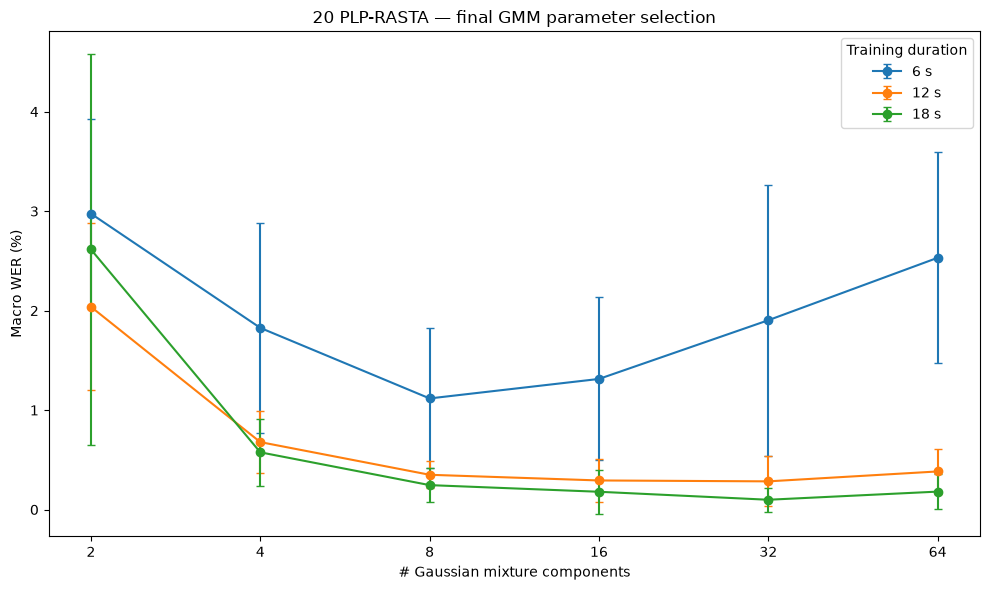

In [22]:
if RUN_FULL_EXPERIMENT:

    fig, ax = plt.subplots(
        figsize=(10, 6)
    )

    for target_seconds in TRAINING_DURATIONS:

        subset = (
            wer_summary[
                wer_summary[
                    "training_seconds_target"
                ] == target_seconds
            ]
            .sort_values(
                "n_components"
            )
        )

        ax.errorbar(
            subset["n_components"],
            subset["WER_mean_percent"],
            yerr=subset["WER_std_percent"],
            marker="o",
            capsize=3,
            label=f"{target_seconds} s",
        )

    ax.set_xscale(
        "log",
        base=2,
    )

    ax.set_xticks(
        N_COMPONENTS_GRID
    )

    ax.set_xticklabels(
        [
            str(value)
            for value in N_COMPONENTS_GRID
        ]
    )

    ax.set(
        title="20 PLP-RASTA — final GMM parameter selection",
        xlabel="# Gaussian mixture components",
        ylabel="Macro WER (%)",
    )

    ax.legend(
        title="Training duration"
    )

    plt.tight_layout()
    plt.show()

## 11. Heat-map-style numeric table

Rows are training durations and columns are GMM model orders. The smallest value is the empirically
best mean WER.

In [23]:
if RUN_FULL_EXPERIMENT:

    parameter_table = (
        wer_summary
        .pivot(
            index="training_seconds_target",
            columns="n_components",
            values="WER_mean_percent",
        )
        .sort_index()
    )

    display(
        parameter_table.round(4)
    )

n_components,2,4,8,16,32,64
training_seconds_target,,,,,,
6,2.9747,1.8265,1.1172,1.3131,1.9033,2.5311
12,2.0382,0.6781,0.3496,0.2925,0.2835,0.3831
18,2.6147,0.5754,0.2457,0.1789,0.0986,0.1804


## 12. Empirical best configuration

This is the literal minimum mean WER observed in the 18 tested parameter combinations.

In [24]:
if RUN_FULL_EXPERIMENT:

    empirical_best = (
        wer_summary
        .sort_values(
            [
                "WER_mean",
                "WER_std",
                "n_components",
            ]
        )
        .iloc[0]
    )

    empirical_best_table = pd.DataFrame([
        {
            "feature": PLP_FEATURE_NAME,
            "training_seconds": int(
                empirical_best[
                    "training_seconds_target"
                ]
            ),
            "n_components": int(
                empirical_best[
                    "n_components"
                ]
            ),
            "WER_mean_percent": float(
                empirical_best[
                    "WER_mean_percent"
                ]
            ),
            "WER_std_percent": float(
                empirical_best[
                    "WER_std_percent"
                ]
            ),
            "WER_se_percent": float(
                empirical_best[
                    "WER_se_percent"
                ]
            ),
            "CI95_low_percent": float(
                empirical_best[
                    "CI95_low_percent"
                ]
            ),
            "CI95_high_percent": float(
                empirical_best[
                    "CI95_high_percent"
                ]
            ),
        }
    ])

    display(
        empirical_best_table.round(4)
    )

,feature,training_seconds,n_components,WER_mean_percent,WER_std_percent,WER_se_percent,CI95_low_percent,CI95_high_percent
0,20_PLP_RASTA,18,32,0.0986,0.12,0.0379,0.0128,0.1844


## 13. One-standard-error rule for model complexity

A tiny numerical advantage should not automatically justify doubling or quadrupling the number of
Gaussian components.

We therefore use the standard **one-standard-error rule**:

1. find the configuration with the lowest mean WER;
2. define the acceptable upper bound as

\[
WER_{best} + SE_{best};
\]

3. keep every configuration whose mean WER is below that bound;
4. among those, choose the **smallest M**;
5. if the same M is available at several durations, prefer the one with the lower mean WER, then the
   longer training duration.

This creates a performance-first but complexity-aware recommendation.

In [25]:
if RUN_FULL_EXPERIMENT:

    best_mean = float(
        empirical_best[
            "WER_mean"
        ]
    )

    best_se = float(
        empirical_best[
            "WER_se"
        ]
    )

    one_se_limit = (
        best_mean
        + best_se
    )

    one_se_candidates = (
        wer_summary[
            wer_summary["WER_mean"]
            <= one_se_limit
        ]
        .copy()
    )

    one_se_candidates = (
        one_se_candidates
        .sort_values(
            [
                "n_components",
                "WER_mean",
                "training_seconds_target",
            ],
            ascending=[
                True,
                True,
                False,
            ],
        )
    )

    recommended = (
        one_se_candidates
        .iloc[0]
    )

    display(
        one_se_candidates[
            [
                "training_seconds_target",
                "n_components",
                "WER_mean_percent",
                "WER_std_percent",
                "WER_se_percent",
            ]
        ].round(4)
    )

    print(
        "One-SE upper limit:",
        round(
            one_se_limit * 100,
            4,
        ),
        "% WER",
    )

,training_seconds_target,n_components,WER_mean_percent,WER_std_percent,WER_se_percent
16,18,32,0.0986,0.12,0.0379


One-SE upper limit: 0.1366 % WER


In [26]:
if RUN_FULL_EXPERIMENT:

    recommended_table = pd.DataFrame([
        {
            "feature": PLP_FEATURE_NAME,
            "training_seconds": int(
                recommended[
                    "training_seconds_target"
                ]
            ),
            "n_components": int(
                recommended[
                    "n_components"
                ]
            ),
            "WER_mean_percent": float(
                recommended[
                    "WER_mean_percent"
                ]
            ),
            "WER_std_percent": float(
                recommended[
                    "WER_std_percent"
                ]
            ),
            "selection_rule": (
                "smallest M within one SE of empirical minimum"
            ),
        }
    ])

    display(
        recommended_table.round(4)
    )

,feature,training_seconds,n_components,WER_mean_percent,WER_std_percent,selection_rule
0,20_PLP_RASTA,18,32,0.0986,0.12,smallest M within one SE of empirical minimum


## 14. Verify consistency with notebook 05 at 12 seconds

Notebook 06 is an extension of the PLP-RASTA branch from notebook 05, not a different implementation.

When the notebook-05 summary is available, this cell compares the 12-second mean WER at every M.

Because the call split and PLP-specific GMM seeds are intentionally matched, the differences should be
numerically negligible.

In [27]:
if (
    RUN_FULL_EXPERIMENT
    and FEATURE05_SUMMARY_PATH.exists()
):

    feature05_summary = pd.read_csv(
        FEATURE05_SUMMARY_PATH
    )

    feature05_plp = (
        feature05_summary[
            feature05_summary["feature"]
            == PLP_FEATURE_NAME
        ][
            [
                "n_components",
                "WER_mean",
            ]
        ]
        .rename(
            columns={
                "WER_mean":
                    "WER_mean_notebook05"
            }
        )
    )

    feature06_12 = (
        wer_summary[
            wer_summary[
                "training_seconds_target"
            ] == 12
        ][
            [
                "n_components",
                "WER_mean",
            ]
        ]
        .rename(
            columns={
                "WER_mean":
                    "WER_mean_notebook06"
            }
        )
    )

    reproducibility_check = (
        feature06_12
        .merge(
            feature05_plp,
            on="n_components",
            how="inner",
        )
    )

    reproducibility_check[
        "absolute_difference"
    ] = np.abs(
        reproducibility_check[
            "WER_mean_notebook06"
        ]
        - reproducibility_check[
            "WER_mean_notebook05"
        ]
    )

    display(
        (
            reproducibility_check
            * {
                "n_components": 1,
                "WER_mean_notebook06": 100,
                "WER_mean_notebook05": 100,
                "absolute_difference": 100,
            }
        ).round(8)
    )

    max_difference = float(
        reproducibility_check[
            "absolute_difference"
        ].max()
    )

    print(
        "Maximum absolute difference:",
        max_difference,
    )

    if max_difference > 1e-10:
        warnings.warn(
            "Notebook 06 does not exactly reproduce notebook 05's 12-s PLP means. "
            "Check whether the feature cache or notebook-05 implementation changed."
        )

else:
    print(
        "Notebook-05 wer_summary.csv not available; "
        "cross-notebook consistency check skipped."
    )

,n_components,WER_mean_notebook06,WER_mean_notebook05,absolute_difference
0,2,2.038244,2.038244,0.0
1,4,0.678102,0.678102,0.0
2,8,0.349589,0.349589,0.0
3,16,0.292525,0.292525,0.0
4,32,0.283508,0.283508,0.0
5,64,0.383135,0.383135,0.0


Maximum absolute difference: 4.5102810375396984e-17


## 15. Per-species behavior of the recommended configuration

A macro-average can hide one difficult class behind eight easy ones. This table therefore reports the
mean classification error of every species under the recommended configuration.

In [28]:
if RUN_FULL_EXPERIMENT:

    recommended_species = (
        per_species_results[
            (
                per_species_results[
                    "training_seconds_target"
                ]
                == int(
                    recommended[
                        "training_seconds_target"
                    ]
                )
            )
            & (
                per_species_results[
                    "n_components"
                ]
                == int(
                    recommended[
                        "n_components"
                    ]
                )
            )
        ]
        .groupby(
            [
                "code",
                "species",
            ],
            as_index=False,
        )
        .agg(
            error_mean=("error_rate", "mean"),
            error_std=("error_rate", "std"),
            validation_calls_mean=(
                "n_validation_calls",
                "mean",
            ),
        )
    )

    recommended_species[
        "error_mean_percent"
    ] = (
        recommended_species[
            "error_mean"
        ]
        * 100
    )

    recommended_species[
        "error_std_percent"
    ] = (
        recommended_species[
            "error_std"
        ]
        * 100
    )

    display(
        recommended_species[
            [
                "code",
                "species",
                "error_mean_percent",
                "error_std_percent",
                "validation_calls_mean",
            ]
        ].round(4)
    )

,code,species,error_mean_percent,error_std_percent,validation_calls_mean
0,f01,Boana alfaroi,0.0000,0.0000,58.1
1,f02,Dendropsophus bifurcus,0.3510,0.7401,56.4
2,f03,Boana cinerascens,0.0719,0.2275,138.3
3,f04,Pristimantis conspicillatus,0.0000,0.0000,142.3
4,f05,Leptodactylus discodactylus,0.0352,0.1113,285.7
5,f06,Osteocephalus fuscifacies,0.0000,0.0000,13.9
6,f07,Boana lanciformis,0.4293,0.6922,69.6
7,f08,Rhinella margaritifera,0.0000,0.0000,79.0
8,f10,Engystomops petersi,0.0000,0.0000,272.9


## 16. Paper result versus recovered-data result

The project should not blur these two outcomes.

The paper result remains the published baseline; our result is the model selection supported by the
recovered corpus and reconstructed feature implementations.

In [29]:
if RUN_FULL_EXPERIMENT:

    paper_vs_observed = pd.DataFrame([
        {
            "source": "PAPER",
            "feature": "20_mFCC",
            "training_duration_statement": (
                "12 s used for feature comparison; "
                "6/12/18 s studied in parameter investigation"
            ),
            "n_components": 64,
            "reason": (
                "authors report modified-filterbank cepstra as best "
                "and select M=64 on average"
            ),
        },
        {
            "source": "OBSERVED_empirical_best",
            "feature": PLP_FEATURE_NAME,
            "training_duration_statement": (
                f"{int(empirical_best['training_seconds_target'])} s"
            ),
            "n_components": int(
                empirical_best["n_components"]
            ),
            "reason": (
                f"minimum recovered-data mean WER "
                f"({empirical_best['WER_mean_percent']:.4f}%)"
            ),
        },
        {
            "source": "RECOMMENDED_parsimonious",
            "feature": PLP_FEATURE_NAME,
            "training_duration_statement": (
                f"{int(recommended['training_seconds_target'])} s"
            ),
            "n_components": int(
                recommended["n_components"]
            ),
            "reason": (
                "smallest GMM order within one standard error "
                "of the empirical minimum"
            ),
        },
    ])

    display(
        paper_vs_observed
    )

,source,feature,training_duration_statement,n_components,reason
0,PAPER,20_mFCC,12 s used for feature comparison; 6/12/18 s st...,64,authors report modified-filterbank cepstra as ...
1,OBSERVED_empirical_best,20_PLP_RASTA,18 s,32,minimum recovered-data mean WER (0.0986%)
2,RECOMMENDED_parsimonious,20_PLP_RASTA,18 s,32,smallest GMM order within one standard error o...


## 17. Final configuration object for notebook 07

Notebook 07 should not guess what won here. The selected configuration is exported explicitly.

Two configurations are saved:

- `empirical_best`
- `recommended_parsimonious`

The detector stage should use `recommended_parsimonious` by default unless there is a documented reason
to prefer the literal empirical minimum.

In [30]:
if RUN_FULL_EXPERIMENT:

    final_selection = {
        "feature": PLP_FEATURE_NAME,
        "feature_dimensions": 20,
        "classes": list(
            USABLE_CODES
        ),
        "excluded_class": "f09",
        "n_repeats": N_REPEATS,
        "training_durations_tested": list(
            TRAINING_DURATIONS
        ),
        "n_components_tested": list(
            N_COMPONENTS_GRID
        ),
        "empirical_best": {
            "training_seconds": int(
                empirical_best[
                    "training_seconds_target"
                ]
            ),
            "n_components": int(
                empirical_best[
                    "n_components"
                ]
            ),
            "WER_mean": float(
                empirical_best[
                    "WER_mean"
                ]
            ),
            "WER_std": float(
                empirical_best[
                    "WER_std"
                ]
            ),
            "WER_se": float(
                empirical_best[
                    "WER_se"
                ]
            ),
        },
        "recommended_parsimonious": {
            "training_seconds": int(
                recommended[
                    "training_seconds_target"
                ]
            ),
            "n_components": int(
                recommended[
                    "n_components"
                ]
            ),
            "WER_mean": float(
                recommended[
                    "WER_mean"
                ]
            ),
            "WER_std": float(
                recommended[
                    "WER_std"
                ]
            ),
            "selection_rule": (
                "smallest M within one standard error of empirical minimum"
            ),
        },
        "paper_reference": {
            "feature": "20_mFCC",
            "n_components": 64,
            "note": (
                "published result; not forced onto recovered-data final model"
            ),
        },
    }

    print(
        json.dumps(
            final_selection,
            indent=2,
        )
    )

{
  "feature": "20_PLP_RASTA",
  "feature_dimensions": 20,
  "classes": [
    "f01",
    "f02",
    "f03",
    "f04",
    "f05",
    "f06",
    "f07",
    "f08",
    "f10"
  ],
  "excluded_class": "f09",
  "n_repeats": 10,
  "training_durations_tested": [
    6,
    12,
    18
  ],
  "n_components_tested": [
    2,
    4,
    8,
    16,
    32,
    64
  ],
  "empirical_best": {
    "training_seconds": 18,
    "n_components": 32,
    "WER_mean": 0.0009860949540346953,
    "WER_std": 0.0011997870868031173,
    "WER_se": 0.0003794059901555998
  },
  "recommended_parsimonious": {
    "training_seconds": 18,
    "n_components": 32,
    "WER_mean": 0.0009860949540346953,
    "WER_std": 0.0011997870868031173,
    "selection_rule": "smallest M within one standard error of empirical minimum"
  },
  "paper_reference": {
    "feature": "20_mFCC",
    "n_components": 64,
    "note": "published result; not forced onto recovered-data final model"
  }
}


## 18. Save all model-selection outputs

In [31]:
if RUN_FULL_EXPERIMENT:

    wer_results.to_csv(
        RESULTS_DIR / "wer_by_repeat.csv",
        index=False,
    )

    wer_summary.to_csv(
        RESULTS_DIR / "wer_summary.csv",
        index=False,
    )

    parameter_table.to_csv(
        RESULTS_DIR / "parameter_table_percent.csv",
    )

    per_species_results.to_csv(
        RESULTS_DIR / "per_species_results.csv",
        index=False,
    )

    recommended_species.to_csv(
        RESULTS_DIR / "recommended_per_species.csv",
        index=False,
    )

    empirical_best_table.to_csv(
        RESULTS_DIR / "empirical_best.csv",
        index=False,
    )

    recommended_table.to_csv(
        RESULTS_DIR / "recommended_configuration.csv",
        index=False,
    )

    paper_vs_observed.to_csv(
        RESULTS_DIR / "paper_vs_observed.csv",
        index=False,
    )

    if STORE_CALL_PREDICTIONS:
        call_predictions.to_csv(
            RESULTS_DIR / "call_predictions.csv",
            index=False,
        )

    with open(
        RESULTS_DIR / "selected_configuration.json",
        "w",
        encoding="utf-8",
    ) as f:
        json.dump(
            final_selection,
            f,
            indent=2,
        )

    print("Saved outputs:")
    for path in sorted(
        RESULTS_DIR.iterdir()
    ):
        print(
            f"  {path.name:<34} "
            f"{path.stat().st_size / 1e6:>8.3f} MB"
        )

Saved outputs:
  call_predictions.csv                 17.853 MB
  empirical_best.csv                    0.000 MB
  paper_vs_observed.csv                 0.000 MB
  parameter_table_percent.csv           0.000 MB
  per_species_results.csv               0.163 MB
  recommended_configuration.csv         0.000 MB
  recommended_per_species.csv           0.001 MB
  selected_configuration.json           0.001 MB
  wer_by_repeat.csv                     0.011 MB
  wer_summary.csv                       0.005 MB


## 16. Recording-level leakage robustness check

### Fixed configuration

- Feature representation: **20 PLP-RASTA**
- Training duration: **18 s per species**
- GMM order: **M = 32**

### Current split

The current experiment performs random selection at the **call level**.

Therefore, different calls extracted from the same source WAV may appear in different partitions.

For example:

- one call from `1101.WAV` may be used for training;
- another call from `1101.WAV` may be used for validation.

This does not leak the same call across partitions, but it may allow the classifier to benefit from recording-specific characteristics such as background noise, microphone response, or acquisition conditions.

### Robustness check

To test whether the very low WER depends on these recording-specific cues, we perform an additional grouped split:

- each complete WAV belongs **only to training or only to validation**;
- no source WAV is allowed to appear in both partitions.

This is a **[ROBUSTNESS CHECK]** introduced in this replication. It is not reported as part of the original paper's experimental protocol.

The objective is to compare:

- **call-level split**: current WER ≈ 0.0986%;
- **recording-level split**: WER under stricter separation.

If performance remains strong under recording-level separation, this provides stronger evidence that the model is learning species-related acoustic structure rather than recording-specific information.

In [32]:
# [ROBUSTNESS CHECK]
# Recording-level split:
# one complete source WAV can belong only to TRAIN or VALIDATION.

ROBUST_TRAINING_SECONDS = 18
ROBUST_N_COMPONENTS = 32
ROBUST_N_REPEATS = 10

if "wav" not in calls.columns:
    raise RuntimeError(
        "calls.csv must contain the 'wav' column "
        "for the recording-level robustness check."
    )


# ---------------------------------------------------------
# 1. Inspect how many independent WAV recordings exist
#    for each species.
# ---------------------------------------------------------

wav_inventory = (
    calls[
        calls["code"].isin(USABLE_CODES)
    ]
    .groupby(
        ["code", "species"],
        as_index=False,
    )
    .agg(
        n_wavs=("wav", "nunique"),
        n_calls=("call_id", "size"),
        total_seconds=("seconds", "sum"),
    )
)

display(
    wav_inventory.round(3)
)

if (wav_inventory["n_wavs"] < 2).any():
    problematic = wav_inventory.loc[
        wav_inventory["n_wavs"] < 2,
        ["code", "n_wavs"],
    ]

    raise RuntimeError(
        "Recording-level validation is impossible for "
        "species represented by fewer than two WAV files:\n"
        f"{problematic}"
    )


# ---------------------------------------------------------
# 2. Global WAV-level split
#
# IMPORTANT:
# The split is GLOBAL, not independently generated for each
# species. Therefore a WAV can never appear in train for one
# species and validation for another species.
# ---------------------------------------------------------

def build_recording_level_split(
    target_seconds,
    repeat,
    max_attempts=5000,
):
    usable_calls = (
        calls[
            calls["code"].isin(
                USABLE_CODES
            )
        ]
        .copy()
        .reset_index(drop=True)
    )

    all_wavs = np.array(
        sorted(
            usable_calls[
                "wav"
            ].astype(str).unique()
        ),
        dtype=object,
    )

    # Duration contributed by every WAV to every species.
    wav_species_seconds = (
        usable_calls
        .groupby(
            ["wav", "code"]
        )["seconds"]
        .sum()
        .unstack(
            fill_value=0.0
        )
        .reindex(
            columns=USABLE_CODES,
            fill_value=0.0,
        )
    )

    base_seed = (
        BASE_SEED
        + 50_000_000
        + repeat * 100_000
        + target_seconds * 100
    )

    for attempt in range(
        max_attempts
    ):
        rng = np.random.default_rng(
            base_seed + attempt
        )

        shuffled_wavs = rng.permutation(
            all_wavs
        )

        train_wavs = []
        accumulated = {
            code: 0.0
            for code in USABLE_CODES
        }

        # Add complete WAVs until every species has
        # at least target_seconds in training.
        for wav in shuffled_wavs:

            contribution = (
                wav_species_seconds.loc[wav]
                if wav in wav_species_seconds.index
                else pd.Series(
                    0.0,
                    index=USABLE_CODES,
                )
            )

            # Only add this WAV if at least one species
            # still needs training material AND this WAV
            # contributes to such a species.
            useful = any(
                (
                    accumulated[code]
                    < target_seconds
                )
                and (
                    float(
                        contribution.get(
                            code,
                            0.0,
                        )
                    )
                    > 0
                )
                for code in USABLE_CODES
            )

            if not useful:
                continue

            train_wavs.append(
                str(wav)
            )

            for code in USABLE_CODES:
                accumulated[code] += float(
                    contribution.get(
                        code,
                        0.0,
                    )
                )

            if all(
                accumulated[code]
                >= target_seconds
                for code in USABLE_CODES
            ):
                break

        # Could not reach 18 s for all species.
        if not all(
            accumulated[code]
            >= target_seconds
            for code in USABLE_CODES
        ):
            continue

        train_wavs = set(
            train_wavs
        )

        validation_wavs = (
            set(all_wavs)
            - train_wavs
        )

        # Absolute leakage check.
        assert train_wavs.isdisjoint(
            validation_wavs
        )

        split = {}
        valid_attempt = True

        for code in USABLE_CODES:

            species_calls = (
                usable_calls[
                    usable_calls["code"]
                    == code
                ]
                .copy()
            )

            train_rows = (
                species_calls[
                    species_calls["wav"]
                    .astype(str)
                    .isin(train_wavs)
                ]
            )

            validation_rows = (
                species_calls[
                    species_calls["wav"]
                    .astype(str)
                    .isin(
                        validation_wavs
                    )
                ]
            )

            # Every species must retain validation calls.
            if validation_rows.empty:
                valid_attempt = False
                break

            train_ids = tuple(
                train_rows[
                    "call_id"
                ]
            )

            validation_ids = tuple(
                validation_rows[
                    "call_id"
                ]
            )

            actual_seconds = float(
                train_rows[
                    "seconds"
                ].sum()
            )

            if (
                actual_seconds
                < target_seconds
            ):
                valid_attempt = False
                break

            # Call leakage check.
            if not set(
                train_ids
            ).isdisjoint(
                validation_ids
            ):
                raise AssertionError(
                    f"Call leakage detected for {code}."
                )

            # WAV leakage check within species.
            species_train_wavs = set(
                train_rows[
                    "wav"
                ].astype(str)
            )

            species_validation_wavs = set(
                validation_rows[
                    "wav"
                ].astype(str)
            )

            if not (
                species_train_wavs
                .isdisjoint(
                    species_validation_wavs
                )
            ):
                raise AssertionError(
                    f"WAV leakage detected for {code}."
                )

            split[code] = {
                "code": code,
                "seed": base_seed + attempt,
                "train_ids": train_ids,
                "validation_ids": validation_ids,
                "target_seconds": target_seconds,
                "actual_seconds": actual_seconds,
                "overshoot_seconds": (
                    actual_seconds
                    - target_seconds
                ),
                "n_train_wavs": len(
                    species_train_wavs
                ),
                "n_validation_wavs": len(
                    species_validation_wavs
                ),
            }

        if valid_attempt:

            return (
                split,
                train_wavs,
                validation_wavs,
                attempt,
            )

    raise RuntimeError(
        "Could not construct a valid WAV-level split "
        f"after {max_attempts} attempts."
    )


# ---------------------------------------------------------
# 3. Run 10 recording-level repetitions with the already
#    selected PLP-RASTA + 18 s + M=32 configuration.
# ---------------------------------------------------------

recording_wer_rows = []
recording_species_blocks = []
recording_prediction_blocks = []
recording_split_rows = []

for repeat in range(
    ROBUST_N_REPEATS
):

    (
        recording_split,
        train_wavs,
        validation_wavs,
        attempt,
    ) = build_recording_level_split(
        target_seconds=ROBUST_TRAINING_SECONDS,
        repeat=repeat,
    )

    # Global leakage invariant.
    assert set(
        train_wavs
    ).isdisjoint(
        validation_wavs
    )

    (
        per_species,
        predictions,
        wer,
    ) = run_condition(
        target_seconds=ROBUST_TRAINING_SECONDS,
        n_components=ROBUST_N_COMPONENTS,
        repeat=repeat,
        split=recording_split,
    )

    recording_species_blocks.append(
        per_species
    )

    recording_prediction_blocks.append(
        predictions
    )

    recording_wer_rows.append({
        "repeat": repeat,
        "training_seconds": (
            ROBUST_TRAINING_SECONDS
        ),
        "n_components": (
            ROBUST_N_COMPONENTS
        ),
        "WER": wer,
        "WER_percent": wer * 100,
        "n_train_wavs": len(
            train_wavs
        ),
        "n_validation_wavs": len(
            validation_wavs
        ),
        "split_attempt": attempt,
    })

    for code in USABLE_CODES:
        info = recording_split[
            code
        ]

        recording_split_rows.append({
            "repeat": repeat,
            "code": code,
            "training_seconds_actual": (
                info[
                    "actual_seconds"
                ]
            ),
            "overshoot_seconds": (
                info[
                    "overshoot_seconds"
                ]
            ),
            "n_train_calls": len(
                info[
                    "train_ids"
                ]
            ),
            "n_validation_calls": len(
                info[
                    "validation_ids"
                ]
            ),
            "n_train_wavs": (
                info[
                    "n_train_wavs"
                ]
            ),
            "n_validation_wavs": (
                info[
                    "n_validation_wavs"
                ]
            ),
        })

    print(
        f"repeat {repeat + 1:>2}/{ROBUST_N_REPEATS} | "
        f"WER={wer * 100:.4f}% | "
        f"train WAVs={len(train_wavs)} | "
        f"validation WAVs={len(validation_wavs)}"
    )


recording_wer_results = pd.DataFrame(
    recording_wer_rows
)

recording_per_species = pd.concat(
    recording_species_blocks,
    ignore_index=True,
)

recording_predictions = pd.concat(
    recording_prediction_blocks,
    ignore_index=True,
)

recording_split_audit = pd.DataFrame(
    recording_split_rows
)


# ---------------------------------------------------------
# 4. Summarize recording-level performance.
# ---------------------------------------------------------

recording_wer_mean = float(
    recording_wer_results[
        "WER"
    ].mean()
)

recording_wer_std = float(
    recording_wer_results[
        "WER"
    ].std()
)

recording_wer_se = (
    recording_wer_std
    / np.sqrt(
        ROBUST_N_REPEATS
    )
)

critical = student_t.ppf(
    0.975,
    df=ROBUST_N_REPEATS - 1,
)

recording_ci_low = (
    recording_wer_mean
    - critical * recording_wer_se
)

recording_ci_high = (
    recording_wer_mean
    + critical * recording_wer_se
)


recording_summary = pd.DataFrame([
    {
        "split": "recording_level",
        "feature": PLP_FEATURE_NAME,
        "training_seconds": (
            ROBUST_TRAINING_SECONDS
        ),
        "n_components": (
            ROBUST_N_COMPONENTS
        ),
        "n_repeats": (
            ROBUST_N_REPEATS
        ),
        "WER_mean_percent": (
            recording_wer_mean
            * 100
        ),
        "WER_std_percent": (
            recording_wer_std
            * 100
        ),
        "WER_se_percent": (
            recording_wer_se
            * 100
        ),
        "CI95_low_percent": (
            recording_ci_low
            * 100
        ),
        "CI95_high_percent": (
            recording_ci_high
            * 100
        ),
    }
])

display(
    recording_summary.round(4)
)


# ---------------------------------------------------------
# 5. Compare directly against the original CALL-level
#    result for 18 s + M=32.
# ---------------------------------------------------------

call_level_reference = (
    wer_summary[
        (
            wer_summary[
                "training_seconds_target"
            ]
            == ROBUST_TRAINING_SECONDS
        )
        & (
            wer_summary[
                "n_components"
            ]
            == ROBUST_N_COMPONENTS
        )
    ]
    .iloc[0]
)

robustness_comparison = pd.DataFrame([
    {
        "split": "call_level",
        "WER_mean_percent": float(
            call_level_reference[
                "WER_mean_percent"
            ]
        ),
        "WER_std_percent": float(
            call_level_reference[
                "WER_std_percent"
            ]
        ),
    },
    {
        "split": "recording_level",
        "WER_mean_percent": (
            recording_wer_mean
            * 100
        ),
        "WER_std_percent": (
            recording_wer_std
            * 100
        ),
    },
])

display(
    robustness_comparison.round(4)
)


# ---------------------------------------------------------
# 6. Per-species recording-level errors.
# ---------------------------------------------------------

recording_species_summary = (
    recording_per_species
    .groupby(
        [
            "code",
            "species",
        ],
        as_index=False,
    )
    .agg(
        error_mean=(
            "error_rate",
            "mean",
        ),
        error_std=(
            "error_rate",
            "std",
        ),
        validation_calls_mean=(
            "n_validation_calls",
            "mean",
        ),
    )
)

recording_species_summary[
    "error_mean_percent"
] = (
    recording_species_summary[
        "error_mean"
    ]
    * 100
)

recording_species_summary[
    "error_std_percent"
] = (
    recording_species_summary[
        "error_std"
    ]
    * 100
)

display(
    recording_species_summary[
        [
            "code",
            "species",
            "error_mean_percent",
            "error_std_percent",
            "validation_calls_mean",
        ]
    ].round(4)
)


# ---------------------------------------------------------
# 7. Split audit.
#    This lets us see how much >18 s training results from
#    grouping complete WAVs.
# ---------------------------------------------------------

display(
    recording_split_audit
    .groupby(
        "code",
        as_index=False,
    )
    .agg(
        training_seconds_mean=(
            "training_seconds_actual",
            "mean",
        ),
        training_seconds_min=(
            "training_seconds_actual",
            "min",
        ),
        training_seconds_max=(
            "training_seconds_actual",
            "max",
        ),
        train_wavs_mean=(
            "n_train_wavs",
            "mean",
        ),
        validation_wavs_mean=(
            "n_validation_wavs",
            "mean",
        ),
    )
    .round(3)
)


# ---------------------------------------------------------
# 8. Save robustness-check outputs.
# ---------------------------------------------------------

recording_wer_results.to_csv(
    RESULTS_DIR
    / "recording_level_wer_by_repeat.csv",
    index=False,
)

recording_summary.to_csv(
    RESULTS_DIR
    / "recording_level_summary.csv",
    index=False,
)

recording_species_summary.to_csv(
    RESULTS_DIR
    / "recording_level_per_species.csv",
    index=False,
)

recording_split_audit.to_csv(
    RESULTS_DIR
    / "recording_level_split_audit.csv",
    index=False,
)

robustness_comparison.to_csv(
    RESULTS_DIR
    / "call_vs_recording_split.csv",
    index=False,
)

print(
    "\\nRecording-level robustness check completed."
)

,code,species,n_wavs,n_calls,total_seconds
0,f01,Boana alfaroi,5,98,44.72
1,f02,Dendropsophus bifurcus,10,99,41.72
2,f03,Boana cinerascens,8,169,102.58
3,f04,Pristimantis conspicillatus,9,186,77.94
4,f05,Leptodactylus discodactylus,3,340,114.36
5,f06,Osteocephalus fuscifacies,5,54,24.94
6,f07,Boana lanciformis,7,101,57.84
7,f08,Rhinella margaritifera,7,96,102.66
8,f10,Engystomops petersi,12,316,134.00


repeat  1/10 | WER=8.1121% | train WAVs=24 | validation WAVs=42
repeat  2/10 | WER=9.4593% | train WAVs=22 | validation WAVs=44
repeat  3/10 | WER=8.6043% | train WAVs=26 | validation WAVs=40
repeat  4/10 | WER=12.4761% | train WAVs=22 | validation WAVs=44
repeat  5/10 | WER=7.5107% | train WAVs=25 | validation WAVs=41
repeat  6/10 | WER=15.0843% | train WAVs=26 | validation WAVs=40
repeat  7/10 | WER=3.5669% | train WAVs=26 | validation WAVs=40
repeat  8/10 | WER=7.6356% | train WAVs=22 | validation WAVs=44
repeat  9/10 | WER=9.1109% | train WAVs=25 | validation WAVs=41
repeat 10/10 | WER=7.1637% | train WAVs=25 | validation WAVs=41


,split,feature,training_seconds,n_components,n_repeats,WER_mean_percent,WER_std_percent,WER_se_percent,CI95_low_percent,CI95_high_percent
0,recording_level,20_PLP_RASTA,18,32,10,8.8724,3.1105,0.9836,6.6472,11.0975


,split,WER_mean_percent,WER_std_percent
0,call_level,0.0986,0.1200
1,recording_level,8.8724,3.1105


,code,species,error_mean_percent,error_std_percent,validation_calls_mean
0,f01,Boana alfaroi,0.0000,0.0000,52.6
1,f02,Dendropsophus bifurcus,5.9450,8.2332,48.1
2,f03,Boana cinerascens,16.5734,23.8352,121.3
3,f04,Pristimantis conspicillatus,12.1622,8.6350,130.9
4,f05,Leptodactylus discodactylus,3.8092,4.5566,181.8
5,f06,Osteocephalus fuscifacies,0.0000,0.0000,11.6
6,f07,Boana lanciformis,14.1494,11.8419,62.5
7,f08,Rhinella margaritifera,4.6914,12.1045,67.6
8,f10,Engystomops petersi,22.5208,17.8392,246.1


,code,training_seconds_mean,training_seconds_min,training_seconds_max,train_wavs_mean,validation_wavs_mean
0,f01,21.128,18.40,27.60,2.3,2.7
1,f02,21.128,18.48,25.62,5.6,4.4
2,f03,28.862,20.72,40.90,2.3,5.7
3,f04,22.934,18.74,30.48,2.5,6.5
4,f05,54.084,47.56,59.28,1.4,1.6
5,f06,19.340,18.14,20.54,3.6,1.4
6,f07,22.752,18.92,29.18,2.7,4.3
7,f08,33.270,26.40,43.20,1.9,5.1
8,f10,29.960,20.94,38.98,2.0,10.0


\nRecording-level robustness check completed.


## 19. Final conclusions

After execution, this notebook establishes the configuration that should drive the next detector stage.

### Interpretation rules

- **Do not replace our selected PLP-RASTA model with m-FCC merely to reproduce the paper's numerical
  choice.**
- **Do preserve the paper result explicitly as the published reference.**
- Prefer the parsimonious recommendation when its WER is statistically indistinguishable from the
  empirical minimum.
- The final detector must be recalibrated from scratch using the chosen PLP-RASTA representation.
  Thresholds obtained previously from m-FCC models are not transferable.

### Next step

`07_final_detector_calibration.ipynb`

That notebook should:

1. load `selected_configuration.json`;
2. use 20 PLP-RASTA;
3. use the selected GMM order;
4. create a fixed leakage-free TRAIN/CALIBRATION partition;
5. fit the frozen GMMs;
6. compute held-out one-vs-all LLR scores;
7. build per-species ROC curves;
8. select thresholds under the desired FPR constraint;
9. freeze and serialize the final model/threshold pair.

Only after that detector is frozen should long-recording inference be revisited.